# Home Credit: Adding bureau and repayment-history data

This Colab notebook compares a neural network using application information only with the same workflow using application information plus applicant-level bureau and installment-payment history. Upload `application_train.csv`, `bureau.csv`, and `installments_payments.csv` before running. A GPU is recommended.


In [1]:
import gc, random, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

df = pd.read_csv('application_train.csv')
assert df.SK_ID_CURR.is_unique
print('Application data:', df.shape, '| Default rate:', f'{df.TARGET.mean():.2%}')


Device: cpu
Application data: (307511, 122) | Default rate: 8.07%


## 1. Aggregate the additional Home Credit tables

In [2]:
# --- Bureau: one summary row per applicant ---
bureau = pd.read_csv('bureau.csv', usecols=['SK_ID_CURR','SK_ID_BUREAU','CREDIT_ACTIVE','DAYS_CREDIT','DAYS_CREDIT_UPDATE','CREDIT_DAY_OVERDUE','CREDIT_CURRENCY','AMT_CREDIT_SUM','AMT_CREDIT_SUM_DEBT'])
bureau = bureau[(bureau.DAYS_CREDIT <= 0) & (bureau.DAYS_CREDIT_UPDATE <= 0)].copy()
bureau['active'] = bureau.CREDIT_ACTIVE.eq('Active').astype(float)
bureau['credit_c1'] = bureau.AMT_CREDIT_SUM.where(bureau.CREDIT_CURRENCY.eq('currency 1'))
bureau['debt_c1'] = bureau.AMT_CREDIT_SUM_DEBT.where(bureau.CREDIT_CURRENCY.eq('currency 1'))
bureau_features = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_LOAN_COUNT=('SK_ID_BUREAU','nunique'), BUREAU_ACTIVE_RATE=('active','mean'),
    BUREAU_LATEST_CREDIT_DAY=('DAYS_CREDIT','max'), BUREAU_MEAN_CREDIT_DAY=('DAYS_CREDIT','mean'),
    BUREAU_MEAN_OVERDUE_DAYS=('CREDIT_DAY_OVERDUE','mean'), BUREAU_MAX_OVERDUE_DAYS=('CREDIT_DAY_OVERDUE','max'),
    BUREAU_MEAN_CREDIT=('credit_c1','mean'), BUREAU_MAX_CREDIT=('credit_c1','max'),
    BUREAU_MEAN_DEBT=('debt_c1','mean'), BUREAU_MAX_DEBT=('debt_c1','max')).reset_index()
bureau_features['BUREAU_HAS_HISTORY'] = 1
assert bureau_features.SK_ID_CURR.is_unique
del bureau; gc.collect()

# --- Installments: combine payment parts, then summarize each applicant ---
inst = pd.read_csv('installments_payments.csv', usecols=['SK_ID_CURR','SK_ID_PREV','NUM_INSTALMENT_VERSION','NUM_INSTALMENT_NUMBER','DAYS_INSTALMENT','DAYS_ENTRY_PAYMENT','AMT_INSTALMENT','AMT_PAYMENT'], dtype={'SK_ID_CURR':'int32','SK_ID_PREV':'int32','NUM_INSTALMENT_VERSION':'float32','NUM_INSTALMENT_NUMBER':'int32','DAYS_INSTALMENT':'float32','DAYS_ENTRY_PAYMENT':'float32'})
inst = inst[(inst.DAYS_INSTALMENT <= 0) & (inst.DAYS_ENTRY_PAYMENT <= 0) & (inst.AMT_INSTALMENT >= 0) & (inst.AMT_PAYMENT >= 0)].copy()
inst['late'] = (inst.DAYS_ENTRY_PAYMENT > inst.DAYS_INSTALMENT).astype('int8')
inst['delay'] = (inst.DAYS_ENTRY_PAYMENT - inst.DAYS_INSTALMENT).clip(lower=0)
pay = inst.groupby(['SK_ID_CURR','SK_ID_PREV','NUM_INSTALMENT_VERSION','NUM_INSTALMENT_NUMBER','DAYS_INSTALMENT'], sort=False).agg(paid=('AMT_PAYMENT','sum'), scheduled_min=('AMT_INSTALMENT','min'), scheduled_max=('AMT_INSTALMENT','max'), late=('late','max'), delay=('delay','max')).reset_index()
del inst; gc.collect()
pay['scheduled'] = pay.scheduled_max.where(pay.scheduled_min.eq(pay.scheduled_max))
pay['ratio'] = pay.paid / pay.scheduled.replace(0,np.nan)
pay['shortfall'] = (pay.paid < pay.scheduled-.01).astype(float)
pay.loc[pay.scheduled.isna(),'shortfall'] = np.nan
inst_features = pay.groupby('SK_ID_CURR').agg(
    INST_SCHEDULE_COUNT=('paid','size'), INST_LOAN_COUNT=('SK_ID_PREV','nunique'),
    INST_LATE_PAYMENT_RATE=('late','mean'), INST_MEAN_PAYMENT_DELAY=('delay','mean'), INST_MAX_PAYMENT_DELAY=('delay','max'),
    INST_MEAN_PAYMENT_RATIO=('ratio','mean'), INST_RECORDED_SHORTFALL_RATE=('shortfall','mean'),
    INST_MEAN_PAYMENT_AMOUNT=('paid','mean'), INST_LATEST_DUE_DAY=('DAYS_INSTALMENT','max')).reset_index()
inst_features['INST_HAS_HISTORY'] = 1
assert inst_features.SK_ID_CURR.is_unique
del pay; gc.collect()

history = bureau_features.merge(inst_features,on='SK_ID_CURR',how='outer',validate='one_to_one')
flags = ['BUREAU_HAS_HISTORY','INST_HAS_HISTORY']
history[flags] = history[flags].fillna(0).astype(int)
full_df = df.merge(history,on='SK_ID_CURR',how='left',validate='one_to_one')
full_df[flags] = full_df[flags].fillna(0).astype(int)
print('Added history features:', history.shape[1]-1)
print('History coverage:', full_df[flags].mean().to_dict())


Added history features: 21
History coverage: {'BUREAU_HAS_HISTORY': 0.856847397328876, 'INST_HAS_HISTORY': 0.9483725785419058}


## 2. Train comparable application-only and history-enriched neural networks

In [3]:
# Same stratified applicant IDs for each model: 64% train, 16% validation, 20% test.
train_val, test_i = train_test_split(np.arange(len(df)),test_size=.20,stratify=df.TARGET,random_state=SEED)
train_i, val_i = train_test_split(train_val,test_size=.20,stratify=df.iloc[train_val].TARGET,random_state=SEED)
y_train=df.iloc[train_i].TARGET.to_numpy(dtype=np.float32); y_val=df.iloc[val_i].TARGET.to_numpy(); y_test=df.iloc[test_i].TARGET.to_numpy()

def arrays(frame):
    X=frame.drop(columns=['TARGET','SK_ID_CURR'])
    cat=X.select_dtypes(include=['object']).columns.tolist(); num=X.select_dtypes(exclude=['object']).columns.tolist()
    prep=ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)])
    return (prep.fit_transform(X.iloc[train_i]).astype(np.float32),prep.transform(X.iloc[val_i]).astype(np.float32),prep.transform(X.iloc[test_i]).astype(np.float32))

class Net(nn.Module):
    def __init__(self,d):
        super().__init__(); self.net=nn.Sequential(nn.Linear(d,128),nn.BatchNorm1d(128),nn.ReLU(),nn.Dropout(.25),nn.Linear(128,64),nn.BatchNorm1d(64),nn.ReLU(),nn.Dropout(.15),nn.Linear(64,1))
    def forward(self,x): return self.net(x).squeeze(1)

def fit(xtr,xval):
    torch.manual_seed(SEED); m=Net(xtr.shape[1]).to(device); loader=DataLoader(TensorDataset(torch.tensor(xtr),torch.tensor(y_train)),batch_size=1024,shuffle=True)
    opt=torch.optim.AdamW(m.parameters(),lr=1e-3,weight_decay=1e-2); loss_fn=nn.BCEWithLogitsLoss(); best_auc=-1; best=None; wait=0; hist=[]; xv=torch.tensor(xval).to(device)
    for epoch in range(1,31):
        m.train(); loss_sum=0
        for xb,yb in loader:
            xb,yb=xb.to(device),yb.to(device); opt.zero_grad(); loss=loss_fn(m(xb),yb); loss.backward(); opt.step(); loss_sum+=loss.item()*len(xb)
        m.eval()
        with torch.no_grad(): p=torch.sigmoid(m(xv)).cpu().numpy()
        auc=roc_auc_score(y_val,p); hist.append((epoch,auc)); print(f'Epoch {epoch:02d}: validation AUC={auc:.5f}')
        if auc>best_auc: best_auc=auc; best={k:v.detach().cpu().clone() for k,v in m.state_dict().items()}; wait=0
        else:
            wait+=1
            if wait>=5: print('Early stopping'); break
    m.load_state_dict(best); return m,best_auc,pd.DataFrame(hist,columns=['epoch','val_auc'])

def score(name,m,xt):
    m.eval()
    with torch.no_grad(): p=torch.sigmoid(m(torch.tensor(xt).to(device))).cpu().numpy()
    label=(p>=.5).astype(int)
    return {'Model':name,'ROC-AUC':roc_auc_score(y_test,p),'Accuracy':accuracy_score(y_test,label),'Precision':precision_score(y_test,label,zero_division=0),'Recall':recall_score(y_test,label,zero_division=0),'F1':f1_score(y_test,label,zero_division=0)}


Application-only input features: 244
Epoch 01: validation AUC=0.73054
Epoch 02: validation AUC=0.73576
Epoch 03: validation AUC=0.73704
Epoch 04: validation AUC=0.73686
Epoch 05: validation AUC=0.73860
Epoch 06: validation AUC=0.73887
Epoch 07: validation AUC=0.73916
Epoch 08: validation AUC=0.73772
Epoch 09: validation AUC=0.73726
Epoch 10: validation AUC=0.73766
Epoch 11: validation AUC=0.73837
Epoch 12: validation AUC=0.73626
Early stopping
Application + history input features: 265
Epoch 01: validation AUC=0.74333
Epoch 02: validation AUC=0.74914
Epoch 03: validation AUC=0.74927
Epoch 04: validation AUC=0.75059
Epoch 05: validation AUC=0.75039
Epoch 06: validation AUC=0.75248
Epoch 07: validation AUC=0.75396
Epoch 08: validation AUC=0.75188
Epoch 09: validation AUC=0.75298
Epoch 10: validation AUC=0.75299
Epoch 11: validation AUC=0.75196
Epoch 12: validation AUC=0.75111
Early stopping


,ROC-AUC,Accuracy,Precision,Recall,F1
Model,,,,,
Application only,0.7466,0.9193,0.0000,0.0000,0.0000
Application + history,0.7555,0.9194,0.6333,0.0038,0.0076


ROC-AUC change after adding history: +0.0089 (+0.89 percentage points)
Best validation AUC: application only=0.7392; with history=0.7540


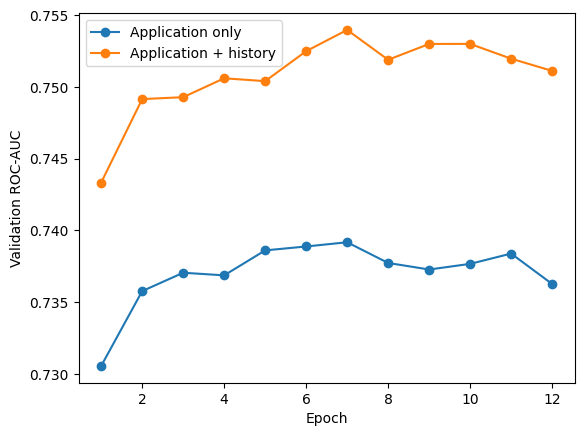

In [4]:
# Application-only model
app_train,app_val,app_test=arrays(df)
print('Application-only input features:',app_train.shape[1])
app_model,app_val_auc,app_hist=fit(app_train,app_val)
app_result=score('Application only',app_model,app_test)

# Application + repayment-history model
hist_train,hist_val,hist_test=arrays(full_df)
print('Application + history input features:',hist_train.shape[1])
hist_model,hist_val_auc,hist_hist=fit(hist_train,hist_val)
hist_result=score('Application + history',hist_model,hist_test)

comparison=pd.DataFrame([app_result,hist_result]).set_index('Model')
display(comparison.style.format('{:.4f}'))
change=hist_result['ROC-AUC']-app_result['ROC-AUC']
print(f'ROC-AUC change after adding history: {change:+.4f} ({change*100:+.2f} percentage points)')
print(f'Best validation AUC: application only={app_val_auc:.4f}; with history={hist_val_auc:.4f}')
plt.plot(app_hist.epoch,app_hist.val_auc,marker='o',label='Application only'); plt.plot(hist_hist.epoch,hist_hist.val_auc,marker='o',label='Application + history'); plt.xlabel('Epoch'); plt.ylabel('Validation ROC-AUC'); plt.legend(); plt.show()


## Interpretation

Adding the bureau credit-history and installment-payment features improved the model’s ability to predict repayment difficulty. The application-only model had a test ROC-AUC of **0.7466**, while the model using both application and repayment-history information had a test ROC-AUC of **0.7555**. This is an improvement of **0.0089 ROC-AUC points**, or about **0.89 percentage points**.

The validation results showed the same pattern: the best validation ROC-AUC increased from **0.7392** for the application-only model to **0.7540** for the model with repayment history. Since the history model performed better on both validation and test data, the improvement appears to be meaningful rather than just random variation from one split.

Accuracy stayed nearly the same at about **91.9%** for both models because repayment difficulty is relatively uncommon in this dataset. Therefore, ROC-AUC is a more useful metric than accuracy for comparing the models. Overall, the results suggest that an applicant’s past borrowing activity and repayment behavior provide useful information beyond their original loan application.